In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read our Excel file into a Pandas DataFrame
df = pd.read_excel("lab3_students.xlsx")

# Display all 12 students
print(df.to_string(index=False))

 Student_ID    Name Group  Study_Hours  Exam_Score  Attendance_Percent
          1     Ali     A            1          50                  70
          2    Vali     A            2          60                  80
          3  Sardor     A            3          65                  85
          4  Madina     A            4          85                  95
          5   Aziza     B            1          55                  75
          6   Jasur     B            2          65                  82
          7 Dilnoza     B            3          75                  90
          8  Kamron     B            4          80                  92
          9  Malika     C            1          60                  78
         10  Bekzod     C            2          68                  83
         11  Nigora     C            3          78                  91
         12   Akmal     C            4          90                  98


/Users/khanmontana/jupyter-env/lib/python3.14/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/Users/khanmontana/jupyter-env/lib/python3.14/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


In [2]:
# Display descriptive statistics for numerical columns
print(df.describe().round(2))

       Student_ID  Study_Hours  Exam_Score  Attendance_Percent
count       12.00        12.00       12.00               12.00
mean         6.50         2.50       69.25               84.92
std          3.61         1.17       12.38                8.48
min          1.00         1.00       50.00               70.00
25%          3.75         1.75       60.00               79.50
50%          6.50         2.50       66.50               84.00
75%          9.25         3.25       78.50               91.25
max         12.00         4.00       90.00               98.00


In [ ]:
# Select only numerical measurements
columns = ["Study_Hours", "Exam_Score", "Attendance_Percent"]
#default describe() method will only show the numerical columns, but we can specify which columns to include in the describe() method by passing a list of column names.
print(df[columns].describe().round(2))

       Study_Hours  Exam_Score  Attendance_Percent
count        12.00       12.00               12.00
mean          2.50       69.25               84.92
std           1.17       12.38                8.48
min           1.00       50.00               70.00
25%           1.75       60.00               79.50
50%           2.50       66.50               84.00
75%           3.25       78.50               91.25
max           4.00       90.00               98.00


In [4]:
# Describe text columns
print(df[["Name", "Group"]].describe())

       Name Group
count    12    12
unique   12     3
top     Ali     A
freq      1     4


In [5]:
# Select exam scores for Group A
scores = df[df["Group"] == "A"]["Exam_Score"]

# Step 1: Calculate the mean
mean_score = sum(scores) / len(scores)

# Step 2: Calculate squared deviations
squared_deviations = [(x - mean_score) ** 2 for x in scores]

# Step 3: Divide by n - 1 and take the square root
manual_std = (sum(squared_deviations) / (len(scores) - 1)) ** 0.5

# Compare manual result with Pandas
print("Mean:", mean_score)
print("Manual standard deviation:", round(manual_std, 4))
print("Pandas standard deviation:", round(scores.std(), 4))

Mean: 65.0
Manual standard deviation: 14.7196
Pandas standard deviation: 14.7196


In [6]:
# Calculate the average exam score for each group
result1 = df.groupby("Group")["Exam_Score"].mean()

print(result1)

Group
A    65.00
B    68.75
C    74.00
Name: Exam_Score, dtype: float64


In [7]:
# Measure how much exam scores vary within each group
result2 = df.groupby("Group")["Exam_Score"].std()

print(result2.round(2))

Group
A    14.72
B    11.09
C    12.96
Name: Exam_Score, dtype: float64


In [8]:
# Find the lowest and highest exam score in each group
result3 = df.groupby("Group")["Exam_Score"].agg(["min", "max"])

print(result3)

       min  max
Group          
A       50   85
B       55   80
C       60   90


In [9]:
# Calculate several statistics simultaneously
result4 = df.groupby("Group")["Exam_Score"].agg(
    ["count", "mean", "median", "std", "sum"]
)

print(result4.round(2))

       count   mean  median    std  sum
Group                                  
A          4  65.00    62.5  14.72  260
B          4  68.75    70.0  11.09  275
C          4  74.00    73.0  12.96  296


In [10]:
# Compare average study hours, scores and attendance
result5 = df.groupby("Group")[
    ["Study_Hours", "Exam_Score", "Attendance_Percent"]
].mean()

print(result5.round(2))

       Study_Hours  Exam_Score  Attendance_Percent
Group                                             
A              2.5       65.00               82.50
B              2.5       68.75               84.75
C              2.5       74.00               87.50


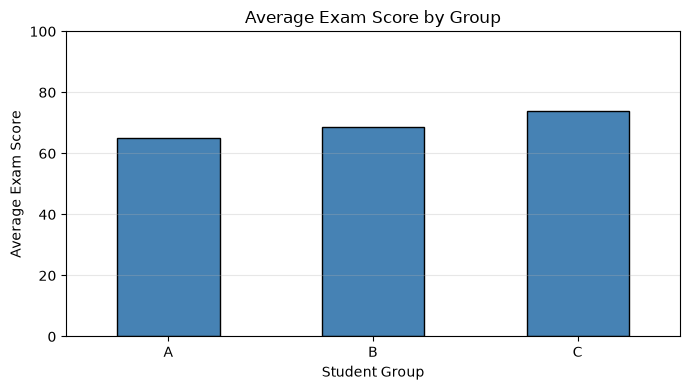

In [11]:
# Calculate average scores
group_means = df.groupby("Group")["Exam_Score"].mean()

# Create a bar chart
plt.figure(figsize=(7, 4))
group_means.plot(kind="bar", color="steelblue", edgecolor="black")

plt.title("Average Exam Score by Group")
plt.xlabel("Student Group")
plt.ylabel("Average Exam Score")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

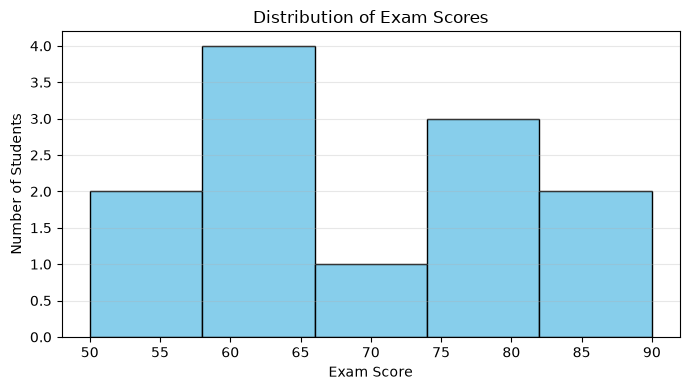

In [12]:
# Create a histogram of exam scores
plt.figure(figsize=(7, 4))

plt.hist(
    df["Exam_Score"],
    bins=5,
    color="skyblue",
    edgecolor="black"
)

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

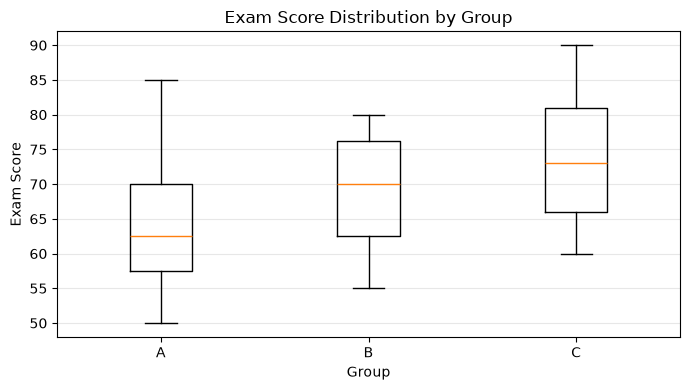

In [13]:
# Separate exam scores by group
group_a = df[df["Group"] == "A"]["Exam_Score"]
group_b = df[df["Group"] == "B"]["Exam_Score"]
group_c = df[df["Group"] == "C"]["Exam_Score"]

plt.figure(figsize=(7, 4))

plt.boxplot(
    [group_a, group_b, group_c],
    tick_labels=["A", "B", "C"]
)

plt.title("Exam Score Distribution by Group")
plt.xlabel("Group")
plt.ylabel("Exam Score")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
# Select Group A
group_a = df[df["Group"] == "A"]

# Calculate Pearson correlation using Pandas
correlation = group_a["Study_Hours"].corr(group_a["Exam_Score"])

# Display the result
print("Pearson correlation:", round(correlation, 4))

Pearson correlation: 0.9648


In [15]:
# Correlation matrix for all three numerical measurements
correlation_matrix = df[
    ["Study_Hours", "Exam_Score", "Attendance_Percent"]
].corr()

print(correlation_matrix.round(3))

                    Study_Hours  Exam_Score  Attendance_Percent
Study_Hours               1.000       0.927               0.950
Exam_Score                0.927       1.000               0.988
Attendance_Percent        0.950       0.988               1.000


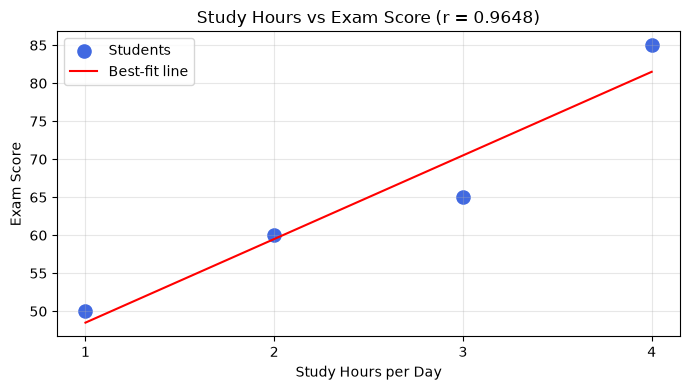

In [16]:
# Use Group A to visualise the manually calculated correlation
group_a = df[df["Group"] == "A"]

x = group_a["Study_Hours"]
y = group_a["Exam_Score"]

# Calculate Pearson correlation
r = x.corr(y)

# Calculate a straight line of best fit
slope, intercept = np.polyfit(x, y, 1)

plt.figure(figsize=(7, 4))

# Plot the actual observations
plt.scatter(x, y, color="royalblue", s=90, label="Students")

# Plot the regression line
plt.plot(
    x,
    slope * x + intercept,
    color="red",
    label="Best-fit line"
)

plt.title(f"Study Hours vs Exam Score (r = {r:.4f})")
plt.xlabel("Study Hours per Day")
plt.ylabel("Exam Score")
plt.xticks([1, 2, 3, 4])
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()